# Tanager-1 Assets: Basic vs Ortho

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/planetlabs/tanager-opendata-edu/blob/main/module_2/03_Basic_vs_Ortho.ipynb)

**Welcome to the third lesson in module 2.**

In the previous lesson, you learned how to choose between Basic and Ortho assets. Here, we put that knowledge into practice: we'll load both geometries for the *same* scene and compare them side-by-side. By the end, you'll see exactly how the raw sensor view (Basic) differs from the map-projected view (Ortho).


## Download the Assets

We'll use a scene over Ringkøbing-Skjern, Denmark, with varied land cover, water, bare soil, and vegetation, so the geometric differences are easy to spot. Download both `basic_sr_hdf5` and `ortho_sr_hdf5` for the scene shown below.

<img class="thumbnail-enhanced" src="https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/thumbnail/20250510_112042_16_4001_thumb.png"
     alt="Tanager 1"
     width="800">

> *All data products from Tanager-1 for 20250510_112042_16_4001 near Ringkøbing-Skjern Municipality, Central Denmark Region, Denmark.*

### 🧰 Your Toolkit so far

You started your Toolkit in **Module 2 · Lesson 1** with `print_structure` and `load_tanager_hdf5`. The cell below is the **reference solution**, compare it with the versions you implemented as last lesson's challenge. Keep this cell near the top of every notebook from now on and **run it before anything else**; you'll keep adding to it as the course goes on.

In [1]:
# ==================
# 🧰 YOUR TOOLKIT
# ==================

# Essential imports for this lesson
import h5py
import numpy as np
import matplotlib.pyplot as plt


# ---- setup -------------------------------------------------------------

def download_tanager_data(url, file_path):
    import os
    import urllib.request

    def _progress(count, block_size, total_size):
        mb_done = count * block_size / 1_000_000
        mb_total = total_size / 1_000_000
        print(f"\rDownloading... {mb_done:.1f} / {mb_total:.1f} MB", end="", flush=True)

    if not os.path.exists(file_path):
        urllib.request.urlretrieve(url, file_path, reporthook=_progress)
        print(f"\nDownload complete: {file_path}")
    else:
        print(f"File already exists, skipping download: {file_path}")
    return file_path

# ---- io ----------------------------------------------------------------

def print_structure(name, obj):
    """Print one HDF5 object (group or dataset) plus its attributes.

    Designed as a callback for ``h5py.File.visititems`` to render the full
    hierarchy of a Tanager-1 file as an indented tree.

    Parameters
    ----------
    name : str
        Full HDF5 path of the object (provided by ``visititems``).
    obj : h5py.Group or h5py.Dataset
        The object itself (provided by ``visititems``).
    """
    level = name.count('/')
    indent = '    ' * level

    if isinstance(obj, h5py.Group):
        print(f"{indent}📂 {name}/")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}📄 {name} | {obj.shape} | {obj.dtype}")

    if len(obj.attrs) > 0:
        for key, val in obj.attrs.items():
            val_str = str(val)
            if len(val_str) > 50:
                val_str = val_str[:50] + "..."
            print(f"{indent}    ↳ 🏷️ {key}: {val_str}")

def load_hdf5(file_path,
                      data_path='HDFEOS/SWATHS/HYP/Data Fields/surface_reflectance',
                      band=None):
    """Load a dataset (or one band) from a Tanager-1 HDF5 file, with its properties.

    Works for ANY dataset in the file — reflectance cubes, masks, geometry layers —
    because it never assumes what the values mean. Pass ``band`` to lazily read a
    single 2-D band straight from disk (cheap on RAM); leave it ``None`` for the
    full array.

    Parameters
    ----------
    file_path : str
        Path to the Tanager-1 ``.h5`` file.
    data_path : str, optional
        Internal HDF5 path to the dataset (Basic ``…/SWATHS/…`` by default; switch
        to ``…/GRIDS/…`` for Ortho, or to any mask / geometry layer).
    band : int, optional
        If given, read only that band index (lazy slice); if ``None``, read all.

    Returns
    -------
    data : ndarray
        The full array, or a single 2-D band if ``band`` is given.
    attrs : dict
        All attributes (properties) of the dataset — e.g. ``'wavelengths'``,
        ``'units'``, ``'good_wavelengths'``.
    """
    with h5py.File(file_path, 'r') as f:
        dset = f[data_path]
        data = dset[:] if band is None else dset[band]
        attrs = dict(dset.attrs)
    return data, attrs


```{note}
As our toolkit grows throughout the course, the documentation sections of previously introduced functions can become quite lengthy and repetitive. To keep the lesson materials focused and easy to follow, future code examples may omit the full docstrings for functions that have already been documented in earlier lessons. Any new function introduced in a lesson will still include its complete documentation. However, when those functions are reused in later lessons, they may appear in an abbreviated form without their docstrings. This helps keep the code concise while preserving all documentation in the lessons where each function is first introduced.
```

In [2]:
# Download the Basic and Ortho SR assets for this scene using your Toolkit's
# download_tanager_data (defined in the Toolkit cell above).
basic_sr_url = "https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/basic_sr_hdf5/20250510_112042_16_4001_basic_sr_hdf5.h5"
ortho_sr_url = "https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_sr_hdf5/20250510_112042_16_4001_ortho_sr_hdf5.h5"

# These filenames are reused throughout the lesson:
# Note: You can change the file name to any name you want.
basic_sr_path = "20250510_112042_16_4001_basic_sr_hdf5.h5"
ortho_sr_path = "20250510_112042_16_4001_ortho_sr_hdf5.h5"

download_tanager_data(basic_sr_url, basic_sr_path)
download_tanager_data(ortho_sr_url, ortho_sr_path)

print("✅ Assets ready")

Downloading... 843.9 / 843.9 MB
Download complete: 20250510_112042_16_4001_basic_sr_hdf5.h5
Downloading... 911.6 / 911.6 MB
Download complete: 20250510_112042_16_4001_ortho_sr_hdf5.h5
✅ Assets ready


## Accessing the Hyperspectral Cubes

To read the hyperspectral data from an HDF5 file, we need the exact path to the dataset inside the file, just as we did in the first lesson of this module. However, **we cannot reuse the data path from that lesson here**.

**Why?** The internal structure of Tanager-1 HDF5 files differs depending on the geometry:

* **Basic** files organize data under a **SWATH** group, which represents the raw satellite strip (sensor geometry).
* **Ortho** files organize data under a **GRID** group, which represents the map-projected view.

Because Basic and Ortho use different root structures, the paths to the reflectance cube are not the same. Before we load the cubes, let's use a lightweight **Tree Viewer** `print_structure` to locate the exact path for each file.

## What to Look For

Scroll through the tree output for each file. You'll see a key structural difference at the top level:

1. **Basic file:** The data lives under `HDFEOS/SWATHS/...` — this confirms you're looking at raw swath (sensor) geometry.
2. **Ortho file:** The data lives under `HDFEOS/GRIDS/...` — this confirms you're looking at projected grid (map) geometry.

Inside each structure, locate the `surface_reflectance` dataset. **Copy the full path** to that dataset for *both* the Basic and Ortho files, we'll use these paths in the next step to load the hyperspectral cubes.

In [3]:
# Basic Surface Reflectance
with h5py.File(basic_sr_path, 'r') as f:
    f.visititems(print_structure)

📂 HDFEOS/
    📂 HDFEOS/ADDITIONAL/
        📂 HDFEOS/ADDITIONAL/FILE_ATTRIBUTES/
    📂 HDFEOS/SWATHS/
        📂 HDFEOS/SWATHS/HYP/
            ↳ 🏷️ created_at: 2025-12-05T23:23:55.300666+00:00
            ↳ 🏷️ strip_id: 20250510_112038_00_4001_strip
            📂 HDFEOS/SWATHS/HYP/Data Fields/
                📄 HDFEOS/SWATHS/HYP/Data Fields/aerosol_optical_depth | (501, 607) | float32
                    ↳ 🏷️ Unit: Unitless
                    ↳ 🏷️ _FillValue: -9999.0
                📄 HDFEOS/SWATHS/HYP/Data Fields/beta_cirrus_mask | (501, 607) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/SWATHS/HYP/Data Fields/beta_cloud_mask | (501, 607) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/SWATHS/HYP/Data Fields/column_water_vapour | (501, 607) | float32
                    ↳ 🏷️ Unit: g/cm^2
                    ↳ 🏷️ _FillValue: -9999.0
                📄 HDFEOS/SWATHS/HYP/Data Fields/nodata_pixels | (501, 607) | uint8
                  

In [4]:
# Ortho Surface Reflectance
with h5py.File(ortho_sr_path, 'r') as f:
    f.visititems(print_structure)

📂 HDFEOS/
    📂 HDFEOS/ADDITIONAL/
        📂 HDFEOS/ADDITIONAL/FILE_ATTRIBUTES/
    📂 HDFEOS/GRIDS/
        📂 HDFEOS/GRIDS/HYP/
            ↳ 🏷️ created_at: 2025-12-05T23:23:28.275751+00:00
            ↳ 🏷️ epsg_code: 32632
            ↳ 🏷️ strip_id: 20250510_112038_00_4001_strip
            📂 HDFEOS/GRIDS/HYP/Data Fields/
                📄 HDFEOS/GRIDS/HYP/Data Fields/aerosol_optical_depth | (724, 847) | float32
                    ↳ 🏷️ Unit: Unitless
                    ↳ 🏷️ _FillValue: -9999.0
                📄 HDFEOS/GRIDS/HYP/Data Fields/beta_cirrus_mask | (724, 847) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/GRIDS/HYP/Data Fields/beta_cloud_mask | (724, 847) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/GRIDS/HYP/Data Fields/column_water_vapour | (724, 847) | float32
                    ↳ 🏷️ Unit: g/cm^2
                    ↳ 🏷️ _FillValue: -9999.0
                📄 HDFEOS/GRIDS/HYP/Data Fields/nodata_pixels | (724, 847) 

## Visualizing the Geometry Shift

With the paths to the `surface_reflectance` dataset for both Basic and Ortho, we can load the hyperspectral cubes and display them side-by-side. Watch for differences in shape and orientation, the raw swath and the map-projected grid will look distinctly different.

In [5]:
# Define the dataset paths (Basic = SWATHS, Ortho = GRIDS)
basic_data_path = 'HDFEOS/SWATHS/HYP/Data Fields/surface_reflectance'
ortho_data_path = 'HDFEOS/GRIDS/HYP/Data Fields/surface_reflectance'

# Define the band
band_number = 100  # Feel free to change the band (0–425)

# Lazy single-band read via your Toolkit loader.
# Passing band=... reads just that 2-D slice straight from disk — no full-cube load.
basic_slice, basic_attrs = load_hdf5(basic_sr_path, basic_data_path, band=band_number)
ortho_slice, ortho_attrs = load_hdf5(ortho_sr_path, ortho_data_path, band=band_number)

# Full cube dimensions without loading the cube: the band count is simply the
# number of wavelengths reported in the dataset's attributes.
basic_bands = len(basic_attrs['wavelengths'])
ortho_bands = len(ortho_attrs['wavelengths'])
print(f"Basic Data Shape (Bands, Rows, Cols): ({basic_bands}, {basic_slice.shape[0]}, {basic_slice.shape[1]})")
print(f"Loaded Basic Slice: {basic_slice.shape}")
print(f"Ortho Data Shape (Bands, Rows, Cols): ({ortho_bands}, {ortho_slice.shape[0]}, {ortho_slice.shape[1]})")
print(f"Loaded Ortho Slice: {ortho_slice.shape}")

Basic Data Shape (Bands, Rows, Cols): (426, 501, 607)
Loaded Basic Slice: (501, 607)
Ortho Data Shape (Bands, Rows, Cols): (426, 724, 847)
Loaded Ortho Slice: (724, 847)


```{admonition} Two Things to Notice
:class: important

**1. Lazy loading (slicing):** We passed `band=band_number` to `load_tanager_hdf5`, so the loader read a single band straight from disk instead of the whole cube. That's lazy loading: HDF5 lets you pull only the slices you need. When you're visualizing just a few bands, prefer `band=` (or raw slicing) over reading the full cube — it saves RAM and keeps your code fast.

**2. Different shapes:** Basic and Ortho files do not have the same dimensions. The Ortho product is typically larger because the rotated satellite swath is fitted into a rectangular map grid during orthorectification. Padding fills in the areas outside the imaged footprint.

```

We've extracted the selected band from both the Basic and Ortho files. Now let's plot them side-by-side to see how the geometry changes between the two views.

* **Left:** Basic — the raw sensor view (unprojected swath).
* **Right:** Ortho — the map-projected view (orthorectified grid).

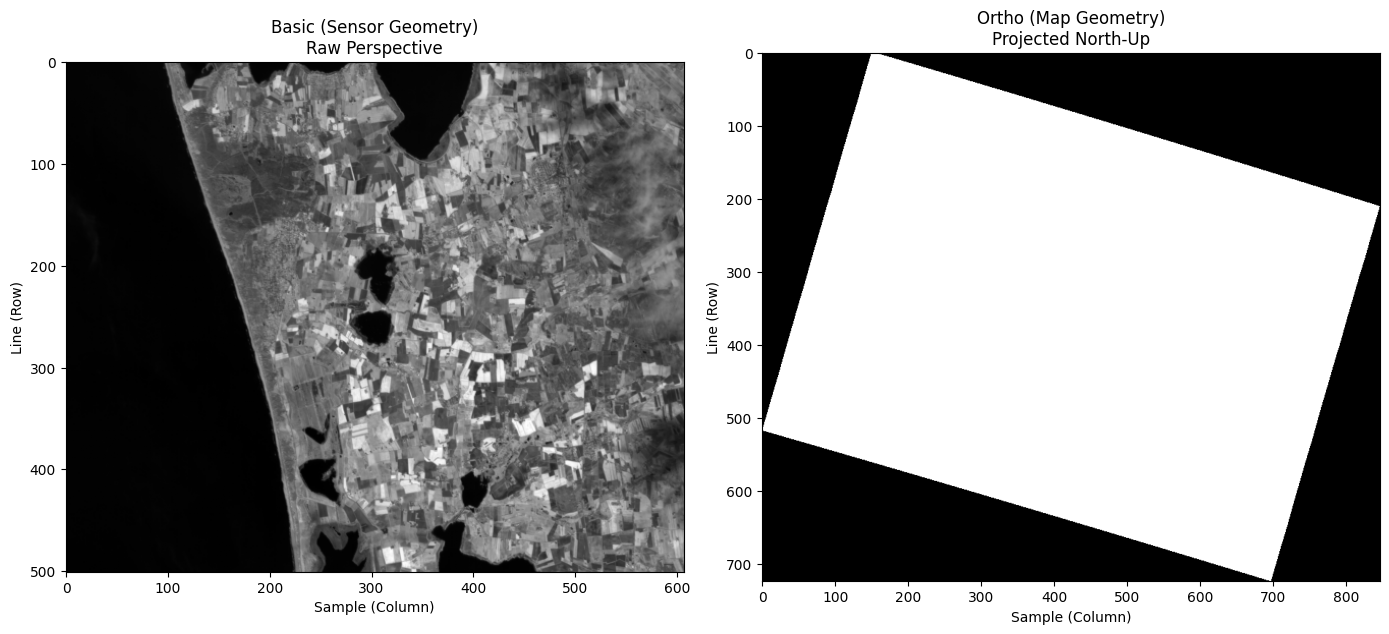

In [6]:
# Create side-by-side figure: unpack axes as (basic, ortho) for clarity
fig, (basic, ortho) = plt.subplots(1, 2, figsize=(14, 8))

# Left: Basic (sensor geometry)
basic.imshow(basic_slice, cmap='gray')
basic.set_title("Basic (Sensor Geometry)\nRaw Perspective")
basic.set_xlabel("Sample (Column)")
basic.set_ylabel("Line (Row)")

# Right: Ortho (map geometry)
ortho.imshow(ortho_slice, cmap='gray')
ortho.set_title("Ortho (Map Geometry)\nProjected North-Up")
ortho.set_xlabel("Sample (Column)")
ortho.set_ylabel("Line (Row)")

plt.tight_layout()
plt.show()

### What went wrong?

If you look at the output, the **Basic** image (left) looks fine, but the **Ortho** image (right) likely appears as a solid white shape on a black background. You can't see the land cover or surface details. Is the file empty?

**No.** The problem is the **fill value** (no-data).

**What's going on?**

1. **Geometry:** Orthorectification rotates the swath to fit a projected map grid. That creates empty corners (areas outside the imaged footprint).
2. **Fill value:** In remote sensing, these empty areas are filled with a value like **`-9999`** so software can identify them as "no data." Tanager-1 follows this convention.

3. **The calculation:** When imshow auto-scaled the display range using the minimum and maximum pixel values, Python used **all** pixels, including the `-9999` fill values. The stretch range became `[-9999, 0.3]`. On that scale, real reflectance values (0.01–0.3) cluster at the top and appear as pure white.

### How can we fix this?

We need to **mask** the fill value (`-9999`) so Python excludes those pixels when computing statistics and visualization. That way, calculations are based only on real reflectance data, and the Ortho image will display correctly.

**Best practice:** Before masking, plot a **histogram** of the band to inspect the distribution. Let's plot and see!

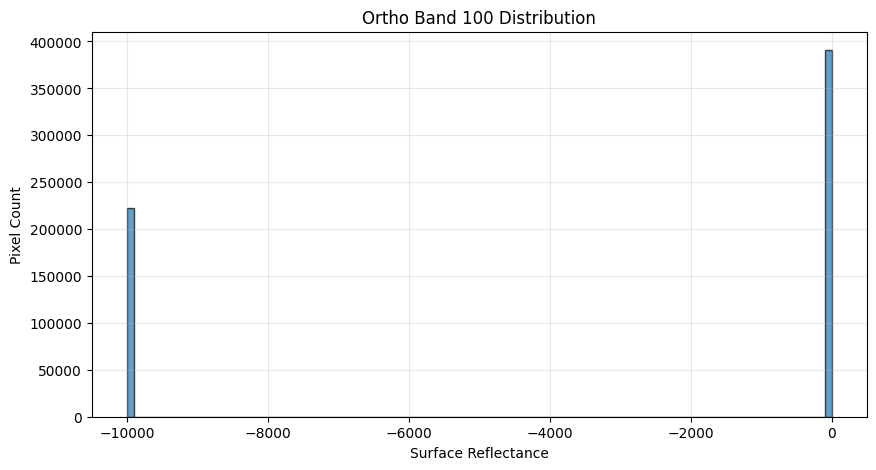

In [7]:
# plot histogram for Ortho Slice

plt.figure(figsize=(10, 5))
plt.hist(ortho_slice.flatten(), bins=100, edgecolor='black', alpha=0.7)
plt.xlabel('Surface Reflectance')
plt.ylabel('Pixel Count')
plt.title(f'Ortho Band {band_number} Distribution')
plt.grid(True, alpha=0.3)
plt.show()

You see the fill-value spike at `-9999`, and there’s also a spike around zero (valid reflectance values). Let’s mask `-9999` as `np.nan` and see what the histogram looks like.

In [8]:
# replace -9999 with np.nan
ortho_slice[ortho_slice == -9999] = np.nan

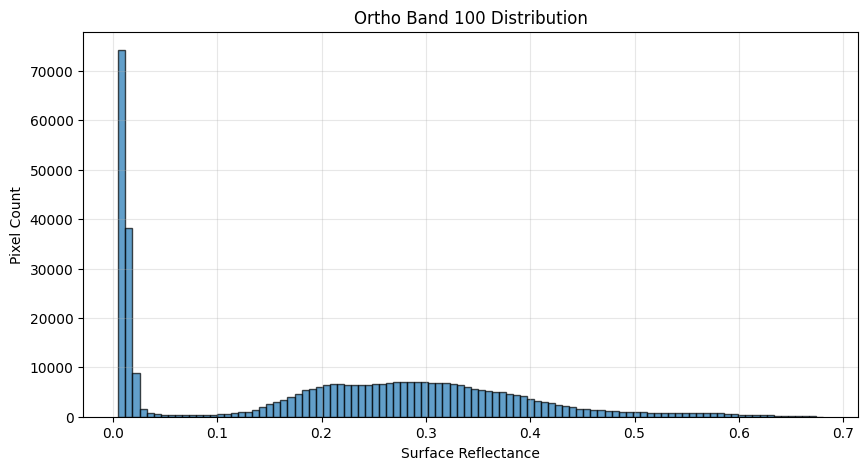

In [9]:
# Replot the histogram after removing `-9999` values
plt.figure(figsize=(10, 5))
plt.hist(ortho_slice.flatten(), bins=100, edgecolor='black', alpha=0.7)
plt.xlabel('Surface Reflectance')
plt.ylabel('Pixel Count')
plt.title(f'Ortho Band {band_number} Distribution')
plt.grid(True, alpha=0.3)
plt.show()

Now, we can compare the Basic and Ortho assets and see the difference.

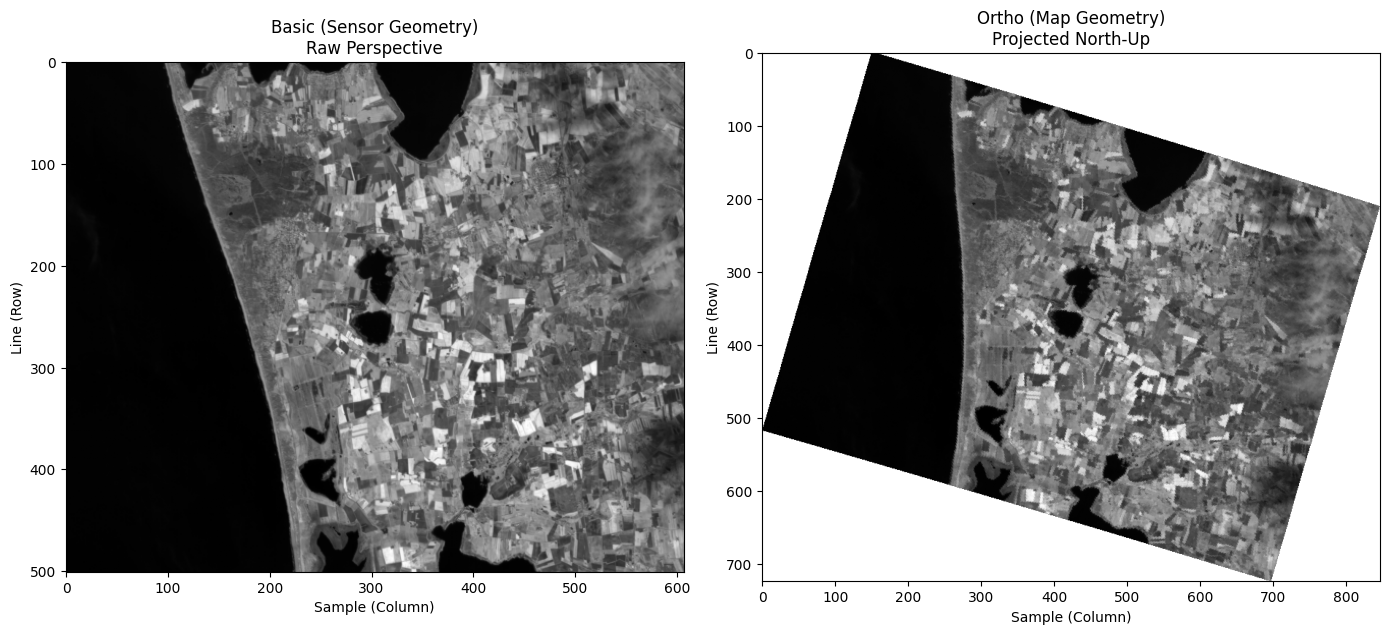

In [10]:
# Create side-by-side figure: unpack axes as (Basic, Ortho) for clarity
fig, (basic, ortho) = plt.subplots(1, 2, figsize=(14, 8))

# Left: Basic (sensor geometry)
basic.imshow(basic_slice, cmap='gray')
basic.set_title("Basic (Sensor Geometry)\nRaw Perspective")
basic.set_xlabel("Sample (Column)")
basic.set_ylabel("Line (Row)")

# Right: Ortho (map geometry)
ortho.imshow(ortho_slice, cmap='gray')
ortho.set_title("Ortho (Map Geometry)\nProjected North-Up")
ortho.set_xlabel("Sample (Column)")
ortho.set_ylabel("Line (Row)")

plt.tight_layout()
plt.show()

Now you can see both assets!

```{note}
In this visualization, we used a direct approach without specifying `vmin` and `vmax`. As practice, you can try adding them.
```

Now that both images display correctly, look closely at the side-by-side comparison. Same patch of Earth, two very different views.

**Key Difference: Raw Perspective vs. Geometric Correction**

* **Basic:** Features like roads, lakes, or agricultural fields may appear warped, compressed, or skewed. *Why:* The sensor is capturing data at an angle and over uneven terrain. A higher (i.e., more off-nadir) viewing angle or elevation changes on the ground may distort how the shapes are captured by the detectors.

* **Ortho:** The features are geometrically corrected and true to their real-world shapes. *Why:* The orthorectification pipeline uses a **DEM (Digital Elevation Model)** to correct for "relief displacement", ironing out the distortions caused by topography and sensor viewing angles. A square field on the ground now maps as a perfect square in the image, allowing it to be seamlessly overlaid with standard maps or vector data.

```{important}
The pixels in the Basic view are "spectrally pure". They represent the original, unaltered light intensity and spectral data captured by the sensor. The Basic asset includes a `geolocation_array` with the latitude and longitude coordinates for each of these measurements. These coordinates are retrieved as part of our geo-orthorectification process and allow you to geolocate the as-measured spectral data.

The pixels in the Ortho view have been projected onto a 30 m UTM map grid. To fit sensor data into the new grid, the pixel values have to be mathematically resampled (interpolated) using a kernel, which can alter the original spectral data. Tanager processing uses a Nearest Neighbor resampling kernel to preserve the spectra. However, you may see some geometric artifacts in the Ortho imagery as a result.
```

```{admonition} Toolkit Update for This Lesson
:class: tip

**No new function this lesson — and that's the point.** A well-designed toolkit function adapts to new situations without a rewrite. Because `load_hdf5` never assumes what its data *means*, the *same* function loaded both **Basic (SWATHS)** and **Ortho (GRIDS)** products, returned each dataset's **properties** (you read the band count straight from `attrs['wavelengths']`), and its `band=` argument did the lazy single-band read for you. That's the payoff of a general API.

**Your challenge before the next lesson:** load the **full** Ortho cube with `cube, attrs = load_hdf5(ortho_sr_path, ortho_data_path)` (no `band=`) and confirm `cube.shape` matches what `print_structure` reported. Then think about the `-9999` problem you just met by hand — in **Module 3 · Lesson 1** we fold no-data handling into the loader itself.
```

---

## Summary & Next Steps

You've compared Basic and Ortho assets side-by-side and seen how geometry transforms from the raw sensor swath to a map-projected grid. Understanding when to use each format is essential for building robust analysis pipelines.

**Next Up:** In Lesson 4 of Module 2, we'll dive into the physics of light, comparing **Radiance** vs **Surface Reflectance** and learning the differences.

See you in **Lesson 4 of Module 2: Radiance vs Reflectance**!